# Task 3 - Regression với clean_data (7).json
Dự đoán giá sản phẩm bằng LinearRegression và DecisionTreeRegressor. Dùng các cột số có sẵn trong clean_data (7).json, giữ cách chia mục và models/scores của bản trước. Đặt JSON cùng thư mục notebook rồi Run All.

## 1. Đọc và chuẩn bị dữ liệu
Dùng các cột price_vnd, rating_num và ba kích thước có sẵn. Dùng trực tiếp các cột số trong bộ mới, không tách lại từ văn bản và không chia 10. Giữ toàn bộ 336 sản phẩm, kể cả sản phẩm giá cao. Dữ liệu gửi sẵn không có ô thiếu ở các cột đầu vào; chưa có thông tin đầy đủ về việc điền thiếu ở bước trước nên không khẳng định toàn bộ lịch sử tiền xử lý đã tránh leakage.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_json("clean_data.json")
print("Kích thước dữ liệu:", df.shape)
print("Số mã sản phẩm trùng:", df["product_id"].duplicated().sum())

features = ["rating_num", "length_cm", "width_cm", "height_cm"]
numeric_cols = ["price_vnd"] + features
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")

X = df[features].copy()
y = df["price_vnd"].copy()


Kích thước dữ liệu: (336, 14)
Số mã sản phẩm trùng: 0


## 2. Chia dữ liệu và xử lý đầu vào
Chia 80% train, 20% test, random_state=42. Median và StandardScaler trong Task 3 chỉ fit trên train, transform test. Giữ SimpleImputer để code vẫn xử lý được ô thiếu nếu có, dù dữ liệu hiện tại không có ô thiếu ở X. Không dùng review, giá, cờ ngoại lệ theo giá, nhãn cụm hay PCA chứa giá làm predictor. Rating có nguồn từ review sinh tự động nên kết quả mang tính thực hành trên bộ dữ liệu này.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Train:", X_train_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (268, 4)
Test: (68, 4)


## 3. Huấn luyện và so sánh hai mô hình
Viết models, scores và vòng for giống Task 4. LinearRegression dự đoán bằng quan hệ tuyến tính; DecisionTreeRegressor chia dữ liệu thành các vùng. MSE, RMSE càng thấp càng tốt; R² càng cao càng tốt và có thể âm. RMSE có đơn vị VND, MSE có đơn vị VND bình phương. Độ sâu 5 là cấu hình ban đầu, chưa tối ưu.

In [3]:
models = {
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(
        max_depth=5, random_state=42
    ),
}

scores = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    scores[name] = {"MSE": mse, "RMSE": rmse, "R2": r2}

    print("\n", name)
    print(f"MSE: {mse:,.2f}")
    print(f"RMSE: {rmse:,.2f} VND")
    print(f"R2: {r2:.4f}")

results = pd.DataFrame(scores).T
print(results)


 LinearRegression
MSE: 3,395,263,973,612.04
RMSE: 1,842,624.21 VND
R2: 0.1626

 DecisionTreeRegressor
MSE: 5,062,816,503,367.91
RMSE: 2,250,070.33 VND
R2: -0.2487
                                MSE          RMSE        R2
LinearRegression       3.395264e+12  1.842624e+06  0.162562
DecisionTreeRegressor  5.062817e+12  2.250070e+06 -0.248738


## 4. Biểu đồ dự đoán và residual
Đường chéo biểu diễn dự đoán đúng hoàn toàn. Residual = giá thực tế trừ giá dự đoán; dương là dự đoán thấp hơn thực tế. Residual phân tán quanh 0 là tín hiệu mong muốn; hình phễu gợi ý phương sai thay đổi. Biểu đồ không tự chứng minh các giả định thống kê.

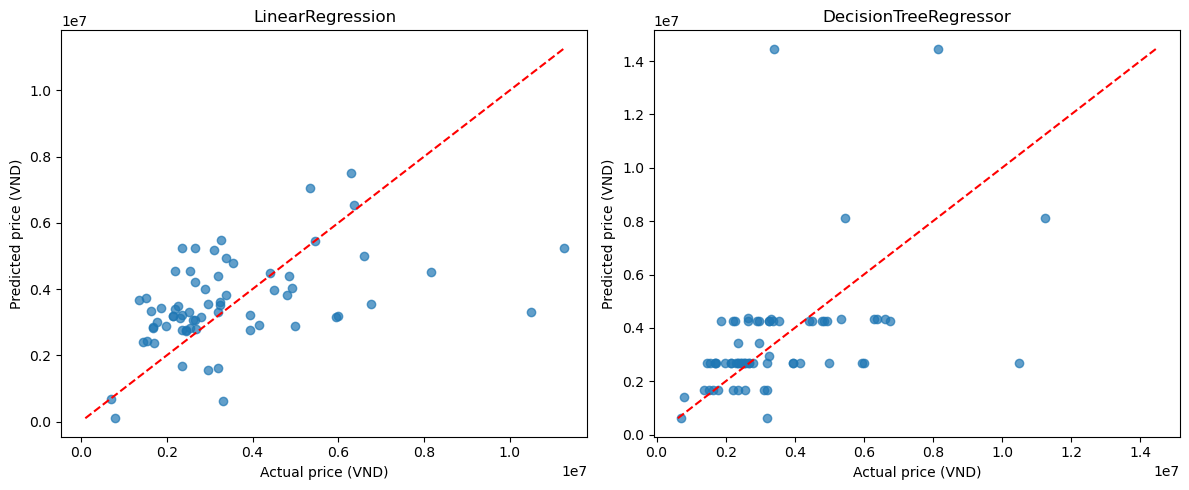

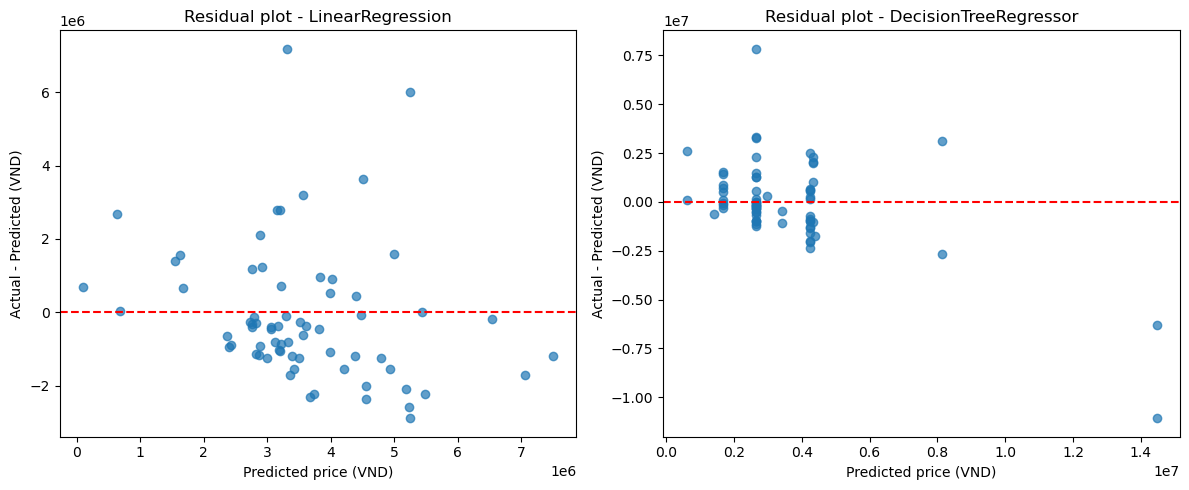

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.7)
    low = min(y_test.min(), y_pred.min())
    high = max(y_test.max(), y_pred.max())
    ax.plot([low, high], [low, high], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual price (VND)")
    ax.set_ylabel("Predicted price (VND)")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred
    ax.scatter(y_pred, residuals, alpha=0.7)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"Residual plot - {name}")
    ax.set_xlabel("Predicted price (VND)")
    ax.set_ylabel("Actual - Predicted (VND)")

plt.tight_layout()
plt.show()

## 5. Kết luận và xuất kết quả
Chọn theo RMSE thấp nhất trên lần chia test hiện tại, giống cách chọn theo F1 trong Task 4. Đây là so sánh trên một lần chia, chưa phải kết quả tối ưu hay ước lượng độc lập sau chọn mô hình. Giữ cả dự đoán âm nếu có để nhìn thấy hạn chế của hồi quy tuyến tính.

In [5]:
best = min(scores, key=lambda name: scores[name]["RMSE"])
print("Mô hình có RMSE thấp nhất trên tập test:", best)
print(f"RMSE: {scores[best]['RMSE']:,.2f} VND")
print(f"R2: {scores[best]['R2']:.4f}")
print("Cần kiểm định chéo trước khi kết luận khả năng tổng quát.")

prediction_df = df.loc[
    X_test.index, ["product_id", "product_name"]
].copy()
prediction_df["Actual_Price"] = y_test

for name, y_pred in predictions.items():
    prediction_df[f"Pred_{name}"] = y_pred
    prediction_df[f"Residual_{name}"] = y_test.to_numpy() - y_pred
    print(name, "- số dự đoán âm:", (y_pred < 0).sum())

results.to_csv("Task5_Streamlit/artifacts/task3_metrics.csv", encoding="utf-8-sig")
print("Đã xuất task3_metrics.csv cho Streamlit")
print(prediction_df.head())

Mô hình có RMSE thấp nhất trên tập test: LinearRegression
RMSE: 1,842,624.21 VND
R2: 0.1626
Cần kiểm định chéo trước khi kết luận khả năng tổng quát.
LinearRegression - số dự đoán âm: 0
DecisionTreeRegressor - số dự đoán âm: 0
Đã xuất task3_metrics.csv cho Streamlit
    product_id                                       product_name  \
72     HBCO078        Bàn họp 240x120cm gỗ cao su hệ CONE HBCO078   
110      ZD037  Bàn có hộp điện 160x70cm gỗ cao su XConcept ZD037   
298    HBXC052  Bàn làm việc 160x60cm gỗ cao su hệ XConcept HB...   
108   BLT68030     Quầy tính tiền 160x60x100cm gỗ cao su BLT68030   
277    HCTA025        Chân sắt lắp ráp 200x120cm hệ Trian HCTA025   

     Actual_Price  Pred_LinearRegression  Residual_LinearRegression  \
72        5450000           5.437669e+06               1.233084e+04   
110       2950000           3.556066e+06              -6.060661e+05   
298       2255000           3.493632e+06              -1.238632e+06   
108       8150000           4.5087

In [6]:

# Lưu trực tiếp các mô hình và bộ tiền xử lý đã fit ở Task 3
from joblib import dump
from pathlib import Path
Path("Task5_Streamlit/artifacts").mkdir(parents=True, exist_ok=True)
dump(imputer, "Task5_Streamlit/artifacts/task3_imputer.joblib")
dump(scaler, "Task5_Streamlit/artifacts/task3_scaler.joblib")
for model_name, trained_model in models.items():
    dump(trained_model, f"Task5_Streamlit/artifacts/task3_{model_name}.joblib")
print("Đã lưu mô hình và preprocessing của Task 3")


Đã lưu mô hình và preprocessing của Task 3
